In [1]:
# Imports

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import shutil

from csaps import csaps
from scipy.stats import pearsonr

# Settings
lake_id = "327"

# Folders and files
data_dir = Path(r"C:\Users\zweifemo\coding\data\cci")
input_file = data_dir / f"{lake_id}.nc"
outlier_dir = data_dir / "outliers"

# Candidate selection
drop_max = 5
z_thresh = 3

# Improvement assessment
n_variants = drop_max
correlation_jump_val = 0.10
correlation_jump_frac = 0.02

In [2]:
# get_candidates function

def get_candidates(
    lake_id: str,
    data_dir: str | Path,
    drop_max: int = 5,
    z_thresh: float = 3,
) -> list[pd.Timestamp]:
    """Select candidate observation dates for a lake.

    A day is eligible if at least one pixel exceeds z_thresh standard
    deviations above its own pixel mean. Eligible days are ranked by
    their spatial chlorophyll-a range, and the highest-ranking days
    are returned.

    Parameters
    ----------
    lake_id : str
        Lake identifier, for example "327" or "310".
    data_dir : str or Path
        Folder containing the extracted lake NetCDF files.
    drop_max : int
        Maximum number of candidate dates to return.
    z_thresh : float
        Minimum number of standard deviations above a pixel mean
        required for a pixel to be considered unusually high.

    Returns
    -------
    list of pd.Timestamp
        Candidate dates in the order in which they should be removed.
    """
    data_dir = Path(data_dir)

    # Find the extracted NetCDF file for the selected lake.
    input_file = data_dir / f"{lake_id}.nc"

    if not input_file.is_file():
        raise FileNotFoundError(f"Input file not found: {input_file}")
    
    # Open the NetCDF file.
    ds = xr.open_dataset(input_file, mask_and_scale=False)

    # Convert Unix timestamps to dates.
    t = pd.to_datetime(ds["time"].values, unit="s")

    # Load chlorophyll-a values and replace missing values.
    data = ds["chla"].values.astype(float)
    data[data == -9999] = np.nan

    # Keep only observations with quality flag 0.
    flags = ds["lwlr_quality_flags"].values
    d = data.copy()
    d[flags != 0] = np.nan

    # Calculate mean and standard deviation over time for each pixel.
    mu = np.nanmean(d, axis=0)
    sd = np.nanstd(d, axis=0)

    # Avoid division by zero.
    sd_safe = np.where(sd > 0, sd, np.nan)

    # Calculate z-values: distance from the pixel mean in units of
    # the pixel standard deviation.
    z = (d - mu) / sd_safe

    # Reshape to one row per day and one column per pixel.
    zflat = z.reshape(len(t), -1)
    dflat = d.reshape(len(t), -1)

    # Highest z-value on each day.
    zmax = np.nanmax(zflat, axis=1)

    # Number of pixels more than z_thresh standard deviations above mean.
    n_pix_gt_thresh = np.sum(zflat > z_thresh, axis=1)

    # Spatial range: highest minus lowest valid value on that day.
    daily_range = (
        np.nanmax(dflat, axis=1)
        - np.nanmin(dflat, axis=1)
    )

    # Create a table with one row per observation day.
    cand = pd.DataFrame({
        "date": t,
        "zmax": zmax,
        "n_pix_gt_thresh": n_pix_gt_thresh,
        "range": daily_range,
    })

    ds.close()

    # Keep only days with at least one unusually high pixel.
    eligible = cand[cand["zmax"] > z_thresh]

    # Rank eligible days by spatial chlorophyll-a range.
    ranked = eligible.sort_values("range", ascending=False)

    # Return the highest-ranking candidate dates.
    cands = list(ranked["date"].head(drop_max))

    return cands

In [3]:
# TEST get_candidates function

cands = get_candidates(
    lake_id=lake_id,
    data_dir=data_dir,
    drop_max=drop_max,
    z_thresh=z_thresh,
)

# Manual modification
# Replace the first automatically selected candidate with 2008-12-13.
# cands[0] = pd.to_datetime("2008-12-13")

print("Selected candidate days:")
for date in cands:
    print(date.strftime("%Y-%m-%d"))

C:\Users\zweifemo\AppData\Local\Temp\ipykernel_27264\4259195299.py:57: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(d, axis=0)
c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Selected candidate days:
2023-01-07
2015-12-10
2015-01-15
2021-09-08
2017-06-11


C:\Users\zweifemo\AppData\Local\Temp\ipykernel_27264\4259195299.py:72: RuntimeWarning: All-NaN slice encountered
  zmax = np.nanmax(zflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_27264\4259195299.py:79: RuntimeWarning: All-NaN slice encountered
  np.nanmax(dflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_27264\4259195299.py:80: RuntimeWarning: All-NaN slice encountered
  - np.nanmin(dflat, axis=1)


In [6]:
# create_updated_input_files variants k0 to k5.

def create_updated_input_files(
    input_file: str | Path,
    candidate_dates: list[pd.Timestamp],
    output_dir: str | Path,
) -> list[Path]:
    """Create updated NetCDF input files for cumulative candidate removal.

    k0 contains all original observations.
    k1 masks the first candidate date.
    k2 masks the first two candidate dates, and so on.

    The original input file is not modified.
    """

    input_file = Path(input_file)
    output_dir = Path(output_dir)

    if not input_file.is_file():
        raise FileNotFoundError(f"Input file not found: {input_file}")

    if not candidate_dates:
        raise ValueError("At least one candidate date is required.")

    # Read the time coordinate from the original file.
    with netCDF4.Dataset(input_file, "r") as dataset:
        time_values = dataset.variables["time"][:]

    # Convert candidate dates to timestamps.
    candidate_timestamps = [
        pd.Timestamp(date)
        for date in candidate_dates
    ]

    # Find the time index of every candidate date.
    candidate_indices = []

    for candidate_timestamp in candidate_timestamps:
        matches = np.flatnonzero(
            pd.to_datetime(time_values, unit="s") == candidate_timestamp
        )

        if len(matches) != 1:
            raise ValueError(
                f"Candidate date does not match exactly one time step: "
                f"{candidate_timestamp.date()}"
            )

        candidate_indices.append(int(matches[0]))

    # Create one file per cumulative removal variant.
    created_files = []

    for number_removed in range(len(candidate_dates) + 1):
        output_file = output_dir / f"k{number_removed}_{input_file.name}"

        # Copy the original file for every variant.
        shutil.copy2(input_file, output_file)

        # Mask the first number_removed candidate dates.
        if number_removed > 0:
            with netCDF4.Dataset(output_file, "r+") as dataset:
                chla = dataset.variables["chla"]

                for candidate_index in candidate_indices[:number_removed]:
                    chla[candidate_index, :, :] = -9999

        created_files.append(output_file)

        removed_dates = candidate_dates[:number_removed]

        print(
            f"Created {output_file.name}: "
            f"{number_removed} candidate date(s) masked"
        )

    return created_files

In [7]:
# TEST create_updated_input_files variants k0 to k5.
# Create the variants and check that each variant masks exactly
# the first k candidate dates.

# Create the k0 to k5 input variants.
updated_input_files = create_updated_input_files(
    input_file=input_file,
    candidate_dates=cands,
    output_dir=outlier_dir,
)

# Check every variant k0 to k5.
all_tests_passed = True

for number_removed in range(len(cands) + 1):
    variant_file = outlier_dir / f"k{number_removed}_{input_file.name}"

    with netCDF4.Dataset(variant_file, "r") as dataset:
        # Read raw values, including the missing-value code -9999.
        dataset.set_auto_mask(False)

        time = pd.to_datetime(
            dataset.variables["time"][:],
            unit="s",
        )
        chla = dataset.variables["chla"][:]

    print(f"\nChecking {variant_file.name}:")
    print(f"Expected masked candidate dates: {number_removed}")

    for candidate_number, candidate_date in enumerate(cands):
        candidate_timestamp = pd.Timestamp(candidate_date)

        matching_positions = np.where(
            time == candidate_timestamp
        )[0]

        if len(matching_positions) != 1:
            print(
                f"  ERROR: {candidate_date.date()} does not match "
                f"exactly one time step."
            )
            all_tests_passed = False
            continue

        candidate_index = int(matching_positions[0])
        candidate_values = chla[candidate_index]

        # A masked day must contain only the missing-value code.
        is_fully_masked = bool(
            np.all(candidate_values == -9999)
        )

        # For this variant, the first number_removed candidate dates
        # must be masked; all later candidate dates must not be masked.
        expected_masked = candidate_number < number_removed

        if expected_masked:
            test_passed = is_fully_masked
            expected_text = "masked"
        else:
            test_passed = not is_fully_masked
            expected_text = "not masked"

        status = "PASS" if test_passed else "FAIL"

        print(
            f"  {candidate_date.date()}: expected {expected_text}, "
            f"fully masked = {is_fully_masked}, {status}"
        )

        if not test_passed:
            all_tests_passed = False

print("\n----------------------------------------")
if all_tests_passed:
    print("ALL TESTS PASSED")
else:
    print("AT LEAST ONE TEST FAILED")

Created k0_327.nc: 0 candidate date(s) masked
Created k1_327.nc: 1 candidate date(s) masked
Created k2_327.nc: 2 candidate date(s) masked
Created k3_327.nc: 3 candidate date(s) masked
Created k4_327.nc: 4 candidate date(s) masked
Created k5_327.nc: 5 candidate date(s) masked

Checking k0_327.nc:
Expected masked candidate dates: 0
  2023-01-07: expected not masked, fully masked = False, PASS
  2015-12-10: expected not masked, fully masked = False, PASS
  2015-01-15: expected not masked, fully masked = False, PASS
  2021-09-08: expected not masked, fully masked = False, PASS
  2017-06-11: expected not masked, fully masked = False, PASS

Checking k1_327.nc:
Expected masked candidate dates: 1
  2023-01-07: expected masked, fully masked = True, PASS
  2015-12-10: expected not masked, fully masked = False, PASS
  2015-01-15: expected not masked, fully masked = False, PASS
  2021-09-08: expected not masked, fully masked = False, PASS
  2017-06-11: expected not masked, fully masked = False, PA

Run phenology fits in PowerShell

```powershell
conda activate cci
cd C:\Users\zweifemo\git\cci-cyano-production

python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k0" -t 1 -l
python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k1" -t 1 -l
python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k2" -t 1 -l
python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k3" -t 1 -l
python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k4" -t 1 -l
python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k5" -t 1 -l
```

Or run all variants in one loop:

```powershell
conda activate cci
cd C:\Users\zweifemo\git\cci-cyano-production

foreach ($k in 0..5) {
    python main.py -f "C:\Users\zweifemo\coding\data\cci\outliers\k$k" -t 1 -l
}
```

In [8]:
# improvement_assessment
# Calculate correlation maps from completed phenology fits and
# assess pixel-wise correlation improvement.

def improvement_assessment(
    outlier_dir: str | Path,
    lake_id: str = "327",
    n_variants: int = 5,
    correlation_jump_val: float = 0.10,
    correlation_jump_frac: float = 0.02,
) -> tuple[pd.DataFrame, dict[int, np.ndarray]]:
    """Calculate correlation maps for k0 to kN and assess improvement.

    Parameters
    ----------
    outlier_dir : str or Path
        Folder containing one subfolder per variant:
        k0, k1, ..., kN. Each subfolder must contain the extracted
        input file and the completed phenology fit.
    lake_id : str
        Lake identifier, for example "327".
    n_variants : int
        Number of removal variants. The function evaluates k0 to kN.
    correlation_jump_val : float
        Minimum absolute correlation gain required for a pixel to
        count as improved.
    correlation_jump_frac : float
        Minimum fraction of baseline pixels required to pass.

    Returns
    -------
    tuple[pd.DataFrame, dict[int, np.ndarray]]
        `results`, one row per removal variant, and `c`, one
        Pearson-correlation map per variant.
    """

    outlier_dir = Path(outlier_dir)

    def calculate_correlation_map(k: int) -> np.ndarray:
        """Calculate one observation-versus-fit correlation per pixel."""

        run_dir = outlier_dir / f"k{k}"

        input_file = run_dir / "extract" / "chla" / f"{lake_id}.nc"
        fit_file = run_dir / "phenology" / "chla" / f"{lake_id}.nc"

        if not input_file.is_file():
            raise FileNotFoundError(f"Input file not found: {input_file}")

        if not fit_file.is_file():
            raise FileNotFoundError(f"Fit file not found: {fit_file}")

        with netCDF4.Dataset(input_file) as observations:
            observations.set_auto_mask(False)

            timestamps = np.array(
                observations.variables["time"][:]
            )
            values = np.array(
                observations.variables["chla"][:]
            )
            quality = np.array(
                observations.variables["lwlr_quality_flags"][:]
            )

        with netCDF4.Dataset(fit_file) as fit:
            fit.set_auto_mask(False)

            smoothing = np.array(
                fit.variables["smoothing_parameter"][:]
            )

        # Convert Unix timestamps to the numeric day scale used by
        # the phenology pipeline.
        time_days = np.array(
            [
                datetime.fromtimestamp(int(ts), tz=timezone.utc).toordinal() - 366
                for ts in timestamps
            ]
        )

        correlations = np.full(smoothing.shape, np.nan)

        # Only pixels with a usable smoothing parameter are evaluated.
        eligible = np.isfinite(smoothing)
        eligible &= (smoothing > 0)
        eligible &= (smoothing < 1)

        for i, j in np.argwhere(eligible):
            pixel_values = values[:, i, j]

            # Excluded candidate days are already coded as -9999.
            valid = (
                (pixel_values != -9999)
                & np.isfinite(pixel_values)
                & (quality[:, i, j] == 0)
            )

            # Require at least four valid observations.
            if valid.sum() < 4:
                continue

            x = time_days[valid]
            y = pixel_values[valid]

            fitted_values = csaps(
                x,
                y,
                x,
                smooth=float(smoothing[i, j]),
            )

            if (
                np.all(np.isfinite(fitted_values))
                and np.ptp(y) > 0
                and np.ptp(fitted_values) > 0
            ):
                correlations[i, j] = pearsonr(
                    y,
                    fitted_values,
                )[0]

        return correlations

    # Calculate correlation maps c0 to cN.
    c = {}

    for k in range(n_variants + 1):
        print(f"Calculating correlations for k{k}...", flush=True)
        c[k] = calculate_correlation_map(k)

    # Pixels with a valid baseline correlation form the reference group.
    baseline_pixels = np.isfinite(c[0])
    n_baseline = int(baseline_pixels.sum())

    if n_baseline == 0:
        raise ValueError("No valid baseline pixels available.")

    required_pixels = int(
        np.ceil(correlation_jump_frac * n_baseline)
    )

    rows = []

    for k in range(1, n_variants + 1):
        change_baseline = c[k] - c[0]
        change_previous = c[k] - c[k - 1]

        improved_baseline = int(np.sum(
            baseline_pixels
            & np.isfinite(change_baseline)
            & (change_baseline >= correlation_jump_val)
        ))

        improved_previous = int(np.sum(
            baseline_pixels
            & np.isfinite(change_previous)
            & (change_previous >= correlation_jump_val)
        ))

        rows.append({
            "variant": f"k{k}",
            "improved_vs_baseline": improved_baseline,
            "percent_vs_baseline": (
                100 * improved_baseline / n_baseline
            ),
            "passes_vs_baseline": (
                improved_baseline >= required_pixels
            ),
            "improved_vs_previous": improved_previous,
            "percent_vs_previous": (
                100 * improved_previous / n_baseline
            ),
            "passes_vs_previous": (
                improved_previous >= required_pixels
            ),
        })

    print(
        f"Baseline pixels: {n_baseline}\n"
        f"Required improved pixels: {required_pixels}"
    )

    results = pd.DataFrame(rows)

    return results, c

In [10]:
# TEST improvement_assessment function.

results, c = improvement_assessment(
    outlier_dir=outlier_dir,
    lake_id=lake_id,
    n_variants=n_variants,
    correlation_jump_val=correlation_jump_val,
    correlation_jump_frac=correlation_jump_frac,
)

display(results.round(2))

Calculating correlations for k0...


c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)


Calculating correlations for k1...
Calculating correlations for k2...
Calculating correlations for k3...
Calculating correlations for k4...
Calculating correlations for k5...
Baseline pixels: 982
Required improved pixels: 20


,variant,improved_vs_baseline,percent_vs_baseline,passes_vs_baseline,improved_vs_previous,percent_vs_previous,passes_vs_previous
0,k1,5,0.51,False,5,0.51,False
1,k2,10,1.02,False,5,0.51,False
2,k3,16,1.63,False,6,0.61,False
3,k4,22,2.24,True,5,0.51,False
4,k5,22,2.24,True,0,0.00,False


| Column | Meaning |
|---|---|
| `improved_vs_baseline` | Number of pixels whose correlation improves by at least 0.10 compared with the baseline `k0`. This is a cumulative comparison. |
| `percent_vs_baseline` | The same number of pixels expressed as a percentage of the baseline pixels. |
| `passes_vs_baseline` | `True` if at least 2% of the baseline pixels improve by at least 0.10. |
| `improved_vs_previous` | Number of pixels whose correlation improves by at least 0.10 compared with the directly preceding variant `k-1`. |
| `percent_vs_previous` | The same number of pixels, but still expressed as a percentage of the baseline pixels. |
| `passes_vs_previous` | `True` if this single additional exclusion alone reaches the 2% threshold. |

In [2]:
# Imports
import sys
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

# File paths
path = Path(r"C:\Users\zweifemo\coding\data\cci\327.nc")
outlier_dir = Path(r"C:\Users\zweifemo\coding\data\cci\outliers")

# Open dataset
ds = xr.open_dataset(path, mask_and_scale=False)

# Display environment and dataset information
print("Python:", sys.executable)
print("File:", path)
print("Dimensions:", dict(ds.sizes))

Python: c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\python.exe
File: C:\Users\zweifemo\coding\data\cci\327.nc
Dimensions: {'time': 3672, 'lat': 37, 'lon': 95}


In [17]:
# Convert Unix timestamps from the file to dates
t = pd.to_datetime(ds["time"].values, unit="s")

print("First day:", t.min())
print("Last day:", t.max())
print("Number of time points:", len(t))

First day: 2002-05-17 00:00:00
Last day: 2023-12-29 00:00:00
Number of time points: 3672


In [18]:
# Load chlorophyll-a values into memory
print("Loading chlorophyll-a values...", flush=True)
data = ds["chla"].values.astype(float)

# Replace the missing-data value with NaN
data[data == -9999] = np.nan

# Flatten each daily map into one row: shape (time, pixels)
flat = data.reshape(data.shape[0], -1)

print("Data shape:", data.shape)
print("Flattened shape:", flat.shape)
print("Data preparation complete.")

Loading chlorophyll-a values...
Data shape: (3672, 37, 95)
Flattened shape: (3672, 3515)
Data preparation complete.


In [19]:
# Exploratory overview — not used for candidate selection
# Calculate the 99th percentile across pixels for each day
print("Calculating daily percentiles...", flush=True)
daily_p99 = np.nanpercentile(flat, 99, axis=1)
print("Daily percentiles calculated.", flush=True)

# Create one row per day with summary statistics
n_valid = np.sum(~np.isnan(flat), axis=1)

df = pd.DataFrame({
    "date": t,
    "p99": daily_p99,
    "max": np.nanmax(flat, axis=1),
    "n_valid": n_valid,
})

print("Days with the highest p99:")
print(df.sort_values("p99", ascending=False).head(10))

print("\nDays with the lowest p99:")
print(df.sort_values("p99").head(10))

Calculating daily percentiles...
Daily percentiles calculated.
Days with the highest p99:
           date         p99         max  n_valid
1802 2015-01-15  212.984070  688.071899      183
2038 2016-01-30  137.641429  139.367111      203
2330 2017-10-30   42.011165   55.645569       31
3134 2021-09-08   34.309766  490.908905      909
1042 2011-04-01   32.503311   36.082565      101
3132 2021-09-06   30.676548   54.663528      930
3194 2021-12-31   30.425050   47.605774       91
1043 2011-04-02   30.422895   45.208023      918
2722 2019-12-10   29.919532   47.205315      100
68   2003-03-31   29.902452   30.044783      241

Days with the lowest p99:
           date       p99       max  n_valid
3082 2021-07-01  0.099452  0.099452        1
2243 2017-05-25  0.164144  0.164492        5
1339 2012-12-16  0.177802  0.177802       53
3374 2022-08-24  0.205554  0.206470        2
3100 2021-07-27  0.236782  0.237395        9
2384 2018-05-01  0.247111  0.247111        1
3115 2021-08-19  0.252878  0.

In [20]:
# Exploratory overview — not used for candidate selection
# Spike indicator: how far is the single largest pixel above the p99?
df["max_over_p99"] = df["max"] / df["p99"]

# Ignore days with very few valid pixels (< 20): too little data to judge
print(df[df["n_valid"] >= 20]
      .sort_values("max_over_p99", ascending=False)
      .head(10))

           date        p99         max  n_valid  max_over_p99
2251 2017-06-11   3.452303  465.859589      924    134.941677
1356 2013-01-16   4.550001  427.508820      721     93.957959
3447 2023-01-07  18.604126  908.326294      768     48.823916
1342 2012-12-26   9.084246  334.174530      501     36.786162
2012 2015-12-10  24.854406  817.815430      552     32.904243
2555 2019-04-01   1.645647   52.059593      641     31.634718
1779 2014-12-09   4.844222  151.329239      682     31.239124
2647 2019-07-30   3.826837  104.874901      666     27.405112
1347 2013-01-02   5.246377  127.148331      702     24.235454
3601 2023-08-30   0.901123   20.310480      814     22.539065


In [21]:
# Exploratory overview — not used for candidate selection
# Find the observation closest to the requested date
def day_index(date):
    return int(np.abs(t - pd.Timestamp(date)).argmin())


# Inspect two high-value days and a nearby comparison day
days = ["2015-01-15", "2016-01-30", "2015-01-21"]
flags = ds["lwlr_quality_flags"].values

for date in days:
    i = day_index(date)

    # Select the five largest non-missing pixel values
    top = np.argsort(
        np.nan_to_num(data[i].ravel(), nan=-np.inf)
    )[-5:]

    print(
        t[i].date(),
        "values:", data[i].ravel()[top],
        "flags:", flags[i].ravel()[top],
        flush=True,
    )

2015-01-15 values: [ 91.85159302  91.85159302 212.98406982 212.98406982 688.07189941] flags: [0 0 0 0 0]
2016-01-30 values: [ 53.08301544  53.08301544 139.36711121 139.36711121 139.36711121] flags: [0 0 0 0 0]
2015-01-21 values: [2.78226733 2.78226733 6.06040859 6.06040859 6.06040859] flags: [0 0 0 0 0]


## 4. Select candidate outlier days

Compare each pixel with its own time series.
Flag unusually high observations, then rank candidate days by
their spatial chlorophyll-a range.

This ranking is a working interpretation of the task, not yet
a confirmed selection rule.

In [22]:
# Keep observations with quality flag 0.
flags = ds["lwlr_quality_flags"].values
d = data.copy()
d[flags != 0] = np.nan

# Calculate the mean and standard deviation over time for each pixel.
mu = np.nanmean(d, axis=0)
sd = np.nanstd(d, axis=0)

# A zero standard deviation cannot be used as a divisor.
sd_safe = np.where(sd > 0, sd, np.nan)

# Express each observation's distance above its pixel mean
# in units of that pixel's standard deviation.
z = (d - mu) / sd_safe

C:\Users\zweifemo\AppData\Local\Temp\ipykernel_19876\315997795.py:7: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(d, axis=0)
C:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [23]:
# One row per day, one column per grid pixel.
zflat = z.reshape(len(t), -1)
dflat = d.reshape(len(t), -1)

# Summarize unusually high observations for each day.
zmax = np.nanmax(zflat, axis=1)
n_out = np.sum(zflat > 3, axis=1)

# Spatial range: highest minus lowest valid value on the same day.
daily_range = (
    np.nanmax(dflat, axis=1)
    - np.nanmin(dflat, axis=1)
)

cand = pd.DataFrame({
    "date": t,
    "zmax": zmax,
    "n_pix_gt3": n_out,
    "range": daily_range,
})

print("Days with at least one pixel above 3 standard deviations:")
print(int((cand["zmax"] > 3).sum()))

print("\nDays with the largest spatial range:")
print("zmax = highest z-value of any pixel on that day; "
      "n_pix_gt3 = number of pixels with z > 3; "
      "range = highest minus lowest valid chlorophyll-a value.")

print(cand.sort_values("range", ascending=False).head(10))

Days with at least one pixel above 3 standard deviations:
1205

Days with the largest spatial range:
zmax = highest z-value of any pixel on that day; n_pix_gt3 = number of pixels with z > 3; range = highest minus lowest valid chlorophyll-a value.
           date       zmax  n_pix_gt3       range
3447 2023-01-07  35.197730         74  908.242969
2012 2015-12-10  43.751967         13  817.802204
1802 2015-01-15  43.063263         27  688.071812
3134 2021-09-08  42.960854        383  490.681064
2251 2017-06-11  35.353992          1  465.753131
1356 2013-01-16  39.209858          4  427.508732
1988 2015-11-06  42.688537         20  416.331765
1342 2012-12-26  42.977952          9  334.152890
2022 2015-12-24  42.740919          7  201.839572
1779 2014-12-09  41.655206          2  151.329119


C:\Users\zweifemo\AppData\Local\Temp\ipykernel_19876\3422692876.py:6: RuntimeWarning: All-NaN slice encountered
  zmax = np.nanmax(zflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_19876\3422692876.py:11: RuntimeWarning: All-NaN slice encountered
  np.nanmax(dflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_19876\3422692876.py:12: RuntimeWarning: All-NaN slice encountered
  - np.nanmin(dflat, axis=1)


In [9]:
def get_candidates(cand, drop_max=5, z_thresh=3):
    """Select high-z candidate days, ranked by spatial range."""
    # Keep only days where at least one pixel is more than
    # z_thresh standard deviations above its own pixel mean.
    eligible = cand[cand["zmax"] > z_thresh]

    # Rank eligible days by spatial range:
    # highest minus lowest valid chlorophyll-a value on that day.
    ranked = eligible.sort_values("range", ascending=False)

    # Select the days with the largest spatial range.
    return list(ranked["date"].head(drop_max))


# Select five candidate days.
cands = get_candidates(cand)

# TEST manually included candidate day
cands[0] = pd.to_datetime("2008-12-13")

# Print cands
print("Selected candidate days:")
for date in cands:
    print(date.strftime("%Y-%m-%d"))

Selected candidate days:
2008-12-13
2015-12-10
2015-01-15
2021-09-08
2017-06-11


### Current experiment: manually included candidate day

The automatic selection ranks days with zmax > 3 by their spatial
chlorophyll-a range.

For this experiment, the first automatically selected day
(2023-01-07) was manually replaced by 2008-12-13.

The day 2008-12-13 passes the zmax > 3 condition but ranks 304th
by spatial range among eligible days. It would therefore not be
selected automatically among the first five candidates.

The results below describe this manually modified candidate set.

In [25]:
# Check why 2008-12-13 is not selected automatically:
# it passes the zmax > 3 filter, but its spatial range
# is not among the five largest.
day = pd.Timestamp("2008-12-13")

# Show the summary values for this test date
print("Summary values for the required day:")
print(
    cand.loc[
        pd.to_datetime(cand["date"]) == day,
        ["date", "zmax", "n_pix_gt3", "range"]
    ].to_string(index=False)
)

# Rank all days with at least one pixel above 3 standard deviations
# by their spatial chlorophyll-a range.
ranked = (
    cand.loc[cand["zmax"] > 3]
    .sort_values("range", ascending=False)
    .reset_index(drop=True)
)

# Find the rank of the required date in this ranking.
position = np.flatnonzero(pd.to_datetime(ranked["date"]) == day)

if len(position):
    print(
        f"\nRank by spatial range among days with zmax > 3: "
        f"{position[0] + 1}"
    )
    print("Only ranks 1 to 5 are selected automatically.")
else:
    print("\nThe manually included day does not pass the zmax > 3 filter.")

Summary values for the required day:
      date      zmax  n_pix_gt3     range
2008-12-13 19.858062        252 27.618545

Rank by spatial range among days with zmax > 3: 304
Only ranks 1 to 5 are selected automatically.


### Temporal context of candidate observations

The current z-score compares each observation with the full
time series of its pixel. It does not account for seasonality
or gaps between valid observations.

Should candidate assessment additionally consider:
- time since the previous and until the next valid observation
- agreement with neighbouring observations
- the seasonal context?

## Setup: create cumulative input variants

Run only when intentionally preparing a new experiment.

This cell copies the original observation file into k0–k5 and
marks candidate-day chlorophyll-a values as missing for the
entire lake.

Existing variant input files are overwritten.
Existing phenology fits are not updated by this cell.

After changing the inputs, matching phenology fits must be
generated before evaluating the experiment.

In [11]:
from pathlib import Path
import shutil
import netCDF4
import numpy as np
import pandas as pd

src = Path(path)
base = Path(r"C:\Users\zweifemo\coding\data\cci\outliers")

print("Original file:", src)
print("Candidate days:", [str(pd.Timestamp(day).date()) for day in cands])

# Check the inputs before creating or modifying any files.
assert src.is_file(), f"Original file not found: {src}"
assert len(cands) == 5, "There should be five candidate days."

# Find the time index of each candidate day.
# Each date must occur exactly once in the time axis.
time_index = pd.DatetimeIndex(t)
indices = []

for day in cands:
    matches = np.flatnonzero(time_index == pd.Timestamp(day))
    assert len(matches) == 1, f"Date missing or duplicated: {day}"
    indices.append(int(matches[0]))

# Create six versions of the file:
# k0 keeps all days, while k1 to k5 progressively
# remove the first 1 to 5 candidate days.
for k in range(6):
    dst = base / f"k{k}" / "extract" / "chla" / "327.nc"

    # Make sure we do not overwrite the original file.
    assert src.resolve() != dst.resolve(), "Source and destination are identical!"

    # Create the output folder and copy the original file.
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    # For k > 0, replace the chlorophyll-a values of the first
    # k candidate days with the missing-value indicator -9999.
    if k > 0:
        with netCDF4.Dataset(str(dst), "r+") as nc:
            nc.variables["chla"][indices[:k], :, :] = -9999

    removed_days = [str(pd.Timestamp(day).date()) for day in cands[:k]]
    print(f"k{k} finished — removed days: {removed_days}")

Original file: C:\Users\zweifemo\coding\data\cci\327.nc
Candidate days: ['2008-12-13', '2015-12-10', '2015-01-15', '2021-09-08', '2017-06-11']
k0 finished — removed days: []
k1 finished — removed days: ['2008-12-13']
k2 finished — removed days: ['2008-12-13', '2015-12-10']
k3 finished — removed days: ['2008-12-13', '2015-12-10', '2015-01-15']
k4 finished — removed days: ['2008-12-13', '2015-12-10', '2015-01-15', '2021-09-08']
k5 finished — removed days: ['2008-12-13', '2015-12-10', '2015-01-15', '2021-09-08', '2017-06-11']


## 5. Check existing input variants

We compare six input variants:

- k0: original observations; no days removed.
- k1: first candidate day removed.
- k2: first two candidate days removed.
- ...
- k5: all five candidate days removed.

Removal is cumulative and follows the order in `cands`.

For each removed day, all chlorophyll-a values are set to the
missing-data value (-9999). The time axis is unchanged.

The original input file is not modified.
The variant files were created earlier and are checked below.

In [26]:
# Check that all six previously created input files exist.
# No files are created or modified.
input_files = []

for k in range(6):
    input_file = (
        outlier_dir / f"k{k}" / "extract" / "chla" / "327.nc"
    )

    exists = input_file.is_file()
    print(f"k{k}: input file exists = {exists}")

    assert exists, f"Missing input file: {input_file}"

    input_files.append(input_file)

k0: input file exists = True
k1: input file exists = True
k2: input file exists = True
k3: input file exists = True
k4: input file exists = True
k5: input file exists = True


## Back up previous phenology results

Before running new phenology fits, any existing `phenology` folders
are renamed to `phenology_old_<timestamp>`.

This preserves previous fits and checkpoints, while freeing the
original `phenology` paths for the new results.

The input variant files themselves are not changed.

In [24]:
## Move any existing phenology result folders aside
## before running new phenology fits.
#from pathlib import Path
#from datetime import datetime
#
## Folder containing the input variants and their results.
#base = Path(r"C:\Users\zweifemo\coding\data\cci\outliers")
#
## Timestamp used to keep multiple backups separate.
#stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
#
## Move any existing phenology result folders aside
## before running new fits.
#for k in range(6):
#    old = base / f"k{k}" / "phenology"
#
#    if old.exists():
#        saved = old.with_name(f"phenology_old_{stamp}")
#        old.rename(saved)
#        print(f"k{k}: old fits and checkpoints backed up")
#    else:
#        print(f"k{k}: no existing phenology folder found")

k0: old fits and checkpoints backed up
k1: old fits and checkpoints backed up
k2: old fits and checkpoints backed up
k3: old fits and checkpoints backed up
k4: old fits and checkpoints backed up
k5: old fits and checkpoints backed up


## 6. Phenology fits — previously completed

A separate phenology run was performed for each input variant
(k0–k5), using the existing repository pipeline.

Observations marked as missing (-9999) were excluded.
With the quality filter enabled, only observations with
QA flag 0 were used.

The JSON files contain run settings, not observations or fit results.

The fits were completed earlier in the terminal.
The commands below are included for reproducibility only.
They do not need to be rerun to inspect the current results.

### PowerShell commands used

Baseline:

```powershell
conda activate cci
cd C:\Users\zweifemo\git\cci-cyano-production\scripts
python main.py -f outlier_k0 -t 1 -l
```

Removal variants:

```powershell
foreach ($k in 1..5) {
    python main.py -f "outlier_k$k" -t 1 -l
}
```

In [11]:
# Check that each phenology output file exists.
output_files = []

for k in range(6):
    output_file = (
        outlier_dir / f"k{k}" / "phenology" / "chla" / "327.nc"
    )

    print(f"k{k}: phenology output exists = {output_file.is_file()}")

    assert output_file.is_file(), f"Missing phenology output: {output_file}"

    output_files.append(output_file)

k0: phenology output exists = True
k1: phenology output exists = True
k2: phenology output exists = True
k3: phenology output exists = True
k4: phenology output exists = True
k5: phenology output exists = True


## 7. Compare observations with fitted curves

For each pixel, take its chlorophyll-a time series and compare
the observed values with the reconstructed curve at the same dates.

This produces one correlation value per pixel:
- closer to +1: stronger positive agreement in variation;
- near 0: little linear relationship;
- negative: opposite variation.

Correlation does not measure the absolute distance from the curve.

Repeat this for k0–k5 to obtain six correlation maps of shape
(37, 95). The next cell compares these maps:
- with k0: cumulative effect of excluding days;
- with k−1: effect of excluding one additional day.

A step qualifies when at least 2% of the baseline pixels gain
at least 0.10 correlation points.

Each variant is currently evaluated on its own remaining
observations, not on identical evaluation data.

In [37]:
import numpy as np
import netCDF4

from pathlib import Path
from csaps import csaps
from scipy.stats import pearsonr
from datetime import datetime, timezone


outlier_dir = Path(
    r"C:\Users\zweifemo\coding\data\cci\outliers"
)


def corr_map(k):
    """Return one observation-versus-curve correlation per pixel."""

    run_dir = outlier_dir / f"k{k}"
    input_file = run_dir / "extract" / "chla" / "327.nc"
    fit_file = run_dir / "phenology" / "chla" / "327.nc"

    # Load this variant's observations and quality flags.
    with netCDF4.Dataset(str(input_file)) as observations:
        observations.set_auto_mask(False)

        timestamps = np.array(
            observations.variables["time"][:]
        )
        values = np.array(
            observations.variables["chla"][:]
        )
        quality = np.array(
            observations.variables["lwlr_quality_flags"][:]
        )

    # Load the smoothing parameter previously determined
    # by the phenology pipeline for each pixel.
    with netCDF4.Dataset(str(fit_file)) as fit:
        fit.set_auto_mask(False)

        smoothing = np.array(
            fit.variables["smoothing_parameter"][:]
        )

    # Convert timestamps to the numeric day scale used by the pipeline.
    time_days = np.array([
        datetime.fromtimestamp(
            int(ts), tz=timezone.utc
        ).toordinal() + 366
        for ts in timestamps
    ])

    # Create a spatial map with one correlation value per pixel.
    # Pixels without a calculable correlation remain NaN.
    correlations = np.full(smoothing.shape, np.nan)

    eligible = (
        np.isfinite(smoothing)
        & (smoothing >= 0)
        & (smoothing <= 1)
    )

    # Process each eligible pixel's full time series.
    for i, j in np.argwhere(eligible):
        pixel_values = values[:, i, j]

        # Keep finite, non-missing observations with QA flag 0.
        # Excluded candidate days have already been set to -9999.
        valid = (
            (pixel_values != -9999)
            & np.isfinite(pixel_values)
            & (quality[:, i, j] == 0)
        )

        # Require at least four valid observations for this evaluation.
        if valid.sum() <= 3:
            continue

        x = time_days[valid]       # Observation dates
        y = pixel_values[valid]   # Observed chlorophyll-a values

        # Reconstruct the curve using the saved smoothing parameter.
        # Evaluate the curve at the valid observation dates.
        fitted_values = csaps(
            x,
            y,
            x,
            smooth=float(smoothing[i, j]),
        )

        # Skip non-finite curve values and constant series.
        if (
            np.all(np.isfinite(fitted_values))
            and np.ptp(y) > 0
            and np.ptp(fitted_values) > 0
        ):
            # Store the correlation at this pixel's spatial position.
            correlations[i, j] = pearsonr(y, fitted_values)[0]

    return correlations


# Calculate one correlation map for each existing variant.
c = {k: corr_map(k) for k in range(6)}

print(
    "Calculated correlation maps for k0–k5. "
    f"Baseline: {np.isfinite(c[0]).sum()} evaluated pixels."
)

Calculated correlation maps for k0–k5. Baseline: 982 evaluated pixels.


### Count improved pixels

Compare the correlation at the same pixel position between variants.

A pixel counts as improved if its correlation increases by at
least 0.10 points. At least 2% of the 982 baseline pixels must
improve, requiring at least 20 pixels.

Two comparisons are shown:
- vs baseline: cumulative change compared with k0;
- vs previous: change after excluding one additional day.

"Pass" means that the comparison reaches the 2% threshold.
It does not prove that the excluded observations were incorrect.
The previous variant is not necessarily a previously accepted fit.

In [38]:
import numpy as np
import pandas as pd

# A pixel must gain at least 0.10 correlation points.
# This is an absolute increase, not a relative increase of 10%.
correlation_jump_val = 0.10

# At least 2% of the baseline pixels must reach that gain.
correlation_jump_frac = 0.02

# Keep the same reference group for all comparisons:
# pixels with a finite correlation in the baseline k0.
baseline_pixels = np.isfinite(c[0])
n_baseline = int(baseline_pixels.sum())

assert n_baseline > 0, "No valid baseline pixels available."

# Round up because we need a whole number of pixels.
# With 982 baseline pixels: 2% = 19.64, so at least 20 are required.
required_pixels = int(
    np.ceil(correlation_jump_frac * n_baseline)
)

rows = []

for k in range(1, 6):
    # Subtract correlations at matching spatial positions.
    # Positive change = higher correlation in the new variant.
    change_baseline = c[k] - c[0]
    change_previous = c[k] - c[k - 1]

    # Count baseline pixels gaining at least 0.10 compared with k0.
    # Pixels with an unavailable comparison do not count as improved.
    improved_baseline = int(np.sum(
        baseline_pixels
        & np.isfinite(change_baseline)
        & (change_baseline >= correlation_jump_val)
    ))

    # Count baseline pixels gaining at least 0.10 compared with k−1.
    improved_previous = int(np.sum(
        baseline_pixels
        & np.isfinite(change_previous)
        & (change_previous >= correlation_jump_val)
    ))

    # Both percentages use the same fixed baseline denominator.
    percent_baseline = (
        100 * improved_baseline / n_baseline
    )
    percent_previous = (
        100 * improved_previous / n_baseline
    )

    # Store one row per exclusion variant.
    rows.append({
        "variant": f"k{k}",
        "improved_vs_baseline": improved_baseline,
        "percent_vs_baseline": percent_baseline,
        "passes_vs_baseline": (
            improved_baseline >= required_pixels
        ),
        "improved_vs_previous": improved_previous,
        "percent_vs_previous": percent_previous,
        "passes_vs_previous": (
            improved_previous >= required_pixels
        ),
    })

results = pd.DataFrame(rows)

print(
    f"Required: at least {required_pixels} of "
    f"{n_baseline} baseline pixels must gain "
    f"≥ {correlation_jump_val:.2f} correlation points."
)

display(results.round(2))

Required: at least 20 of 982 baseline pixels must gain ≥ 0.10 correlation points.


,variant,improved_vs_baseline,percent_vs_baseline,passes_vs_baseline,improved_vs_previous,percent_vs_previous,passes_vs_previous
0,k1,5,0.51,False,5,0.51,False
1,k2,10,1.02,False,5,0.51,False
2,k3,16,1.63,False,6,0.61,False
3,k4,22,2.24,True,5,0.51,False
4,k5,22,2.24,True,0,0.00,False


### Result run WITH 2008-12-13

The candidate days are `2008-12-13`, `2015-12-10`, `2015-01-15`,
`2021-09-08`, and `2017-06-11`.

The baseline contains 982 pixels with a valid correlation.
At least 20 pixels must improve by 0.10 or more to reach the
2% success threshold.

Removing `2008-12-13` alone (`k1`) improves the correlation by at
least 0.10 for 5 pixels, corresponding to 0.51% of the baseline
pixels. The starting criterion is not yet met.

The criterion is reached after removing four candidate days:
`k4` and `k5` each improve the correlation by at least 0.10 for
22 pixels, corresponding to 2.24% of the baseline pixels.

The correlation maps differ between all removal variants, confirming
that the updated input files and fits were used. However, the overall
improvement is small and appears only after removing several candidate
days.

This result applies to the current candidate order and the
baseline-pixel denominator. It does not prove that the candidate
observations are valid or invalid.

### Previous experiment: automatic candidate selection

In the previous experiment, the first candidate was 2023-01-07.
In the current experiment, it was manually replaced by 2008-12-13.
The other four candidates and their order were unchanged.

Baseline pixels: 982  
Required improved pixels: 20

| Variant | Improved vs baseline | Percent vs baseline | Improved vs previous | Passes vs baseline |
|---------|---------------------:|--------------------:|---------------------:|--------------------|
| k1 | 2  | 0.20% | 2 | False |
| k2 | 7  | 0.71% | 5 | False |
| k3 | 12 | 1.22% | 6 | False |
| k4 | 16 | 1.63% | 5 | False |
| k5 | 16 | 1.63% | 0 | False |

The previous experiment does not reach the cumulative baseline
threshold. Values are taken from the saved outputs of
`outlier_explore_moritz_1.ipynb`.

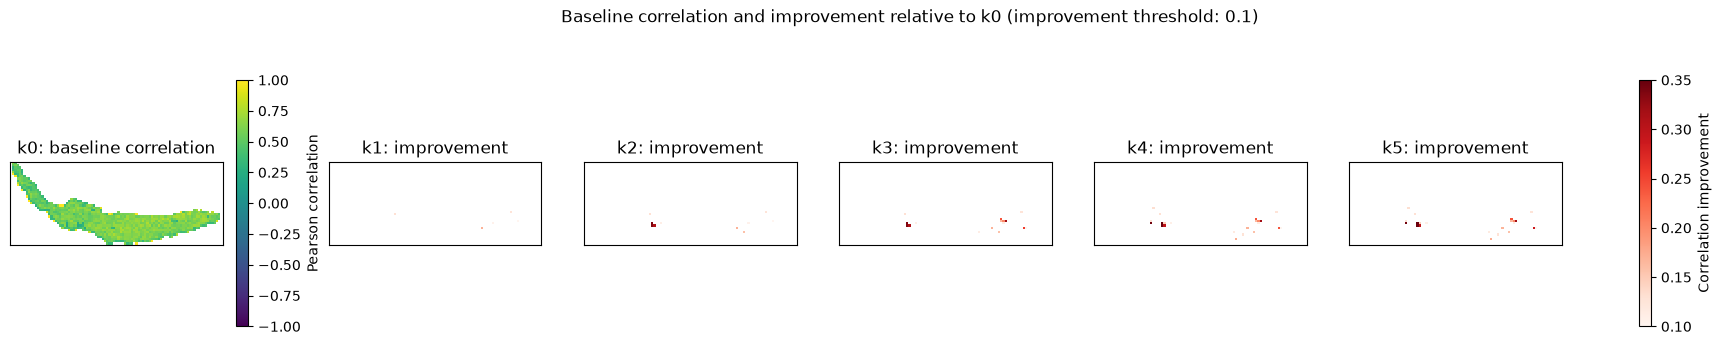

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Folder for the saved figure.
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Improvement threshold and common colour scale.
correlation_jump_val = 0.10
vmax = 0.35

fig, axes = plt.subplots(
    nrows=1,
    ncols=6,
    figsize=(24, 4),
)

# First panel: baseline correlation map k0.
im0 = axes[0].imshow(
    c[0],
    cmap="viridis",
    vmin=-1,
    vmax=1,
    interpolation="nearest",
)
axes[0].set_title("k0: baseline correlation")
axes[0].set_xticks([])
axes[0].set_yticks([])

# Remaining panels: correlation improvement relative to k0.
for ax, k in zip(axes[1:], range(1, 6)):
    change = c[k] - c[0]

    improved = np.where(
        change >= correlation_jump_val,
        change,
        np.nan,
    )

    im = ax.imshow(
        improved,
        cmap="Reds",
        vmin=correlation_jump_val,
        vmax=vmax,
        interpolation="nearest",
    )

    ax.set_title(f"k{k}: improvement")
    ax.set_xticks([])
    ax.set_yticks([])

# Colour bar for the baseline correlation.
fig.colorbar(
    im0,
    ax=axes[0],
    shrink=0.8,
    label="Pearson correlation",
)

# Shared colour bar for the improvement maps.
fig.colorbar(
    im,
    ax=axes[1:].ravel().tolist(),
    shrink=0.8,
    label="Correlation improvement",
)

fig.suptitle(
    "Baseline correlation and improvement relative to k0 "
    f"(improvement threshold: {correlation_jump_val})"
)

# Display the complete figure directly in the notebook.
plt.show()

## Visualise correlation changes

For each removal variant, we compare its correlation map with the
baseline fit `k0`.

The first map shows the correlation change:

- Red: correlation increased after removing the candidate days.
- Blue: correlation decreased.
- White: little or no change.

The second map highlights only pixels that improve by at least 0.10

## Inspect time-series fits: k0 versus k4

Compare the baseline with the first cumulative removal variant
that meets the baseline success criterion.

Examples:
- pixel with the largest correlation increase;
- pixel with the largest correlation decrease;
- pixel with a correlation change close to zero.

Grey points show valid baseline observations.
Orange crosses mark observations excluded in k4.
Lines reconstruct the smoothing splines using each variant's
observations and saved smoothing parameter.

The correlations shown use each variant's own observations,
matching the current correlation-map calculation.
They are not an independent validation.

C:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)
C:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)


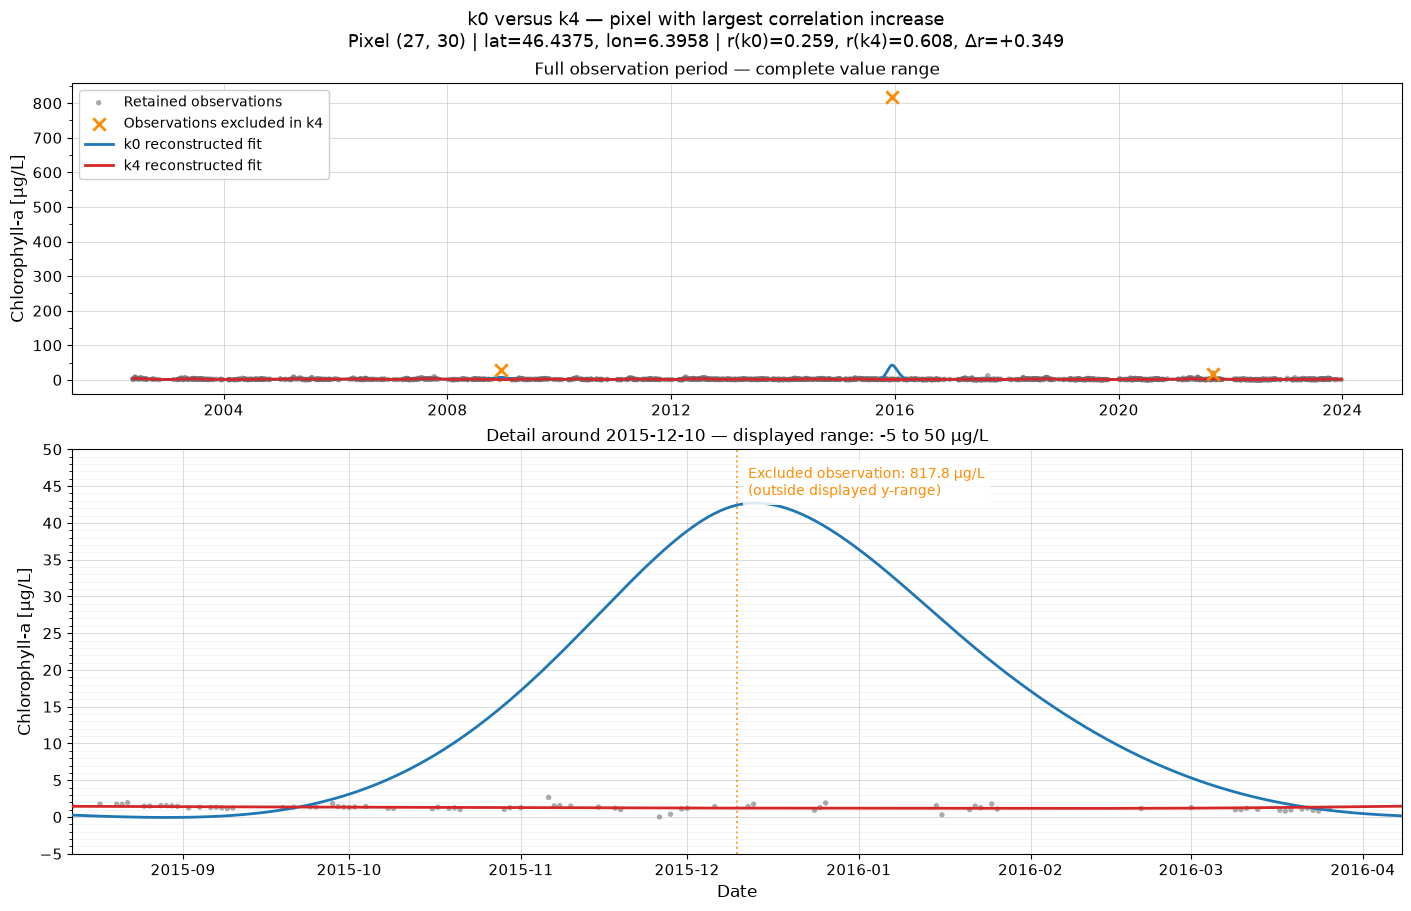

In [12]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4

from pathlib import Path
from csaps import csaps
from datetime import datetime, timezone
from matplotlib.ticker import MultipleLocator, AutoMinorLocator


# Settings
outlier_dir = Path(
    r"C:\Users\zweifemo\coding\data\cci\outliers"
)

plot_dir = Path("output") / "fit_examples"
plot_dir.mkdir(parents=True, exist_ok=True)

detail_ymin = -5
detail_ymax = 50
detail_major_step = 5
detail_minor_step = 1
window_days = 120

assert "c" in globals(), "Run the correlation-map calculation first."
assert 0 in c and 4 in c, "Correlation maps for k0 and k4 are required."


def load_pixel_fit(k, i, j):
    run_dir = outlier_dir / f"k{k}"
    input_file = run_dir / "extract" / "chla" / "327.nc"
    fit_file = run_dir / "phenology" / "chla" / "327.nc"

    assert input_file.is_file(), f"Missing input: {input_file}"
    assert fit_file.is_file(), f"Missing fit: {fit_file}"

    with netCDF4.Dataset(str(input_file)) as nc:
        nc.set_auto_mask(False)

        timestamps = np.asarray(nc.variables["time"][:])
        values = np.asarray(
            nc.variables["chla"][:, i, j],
            dtype=float,
        )
        quality = np.asarray(
            nc.variables["lwlr_quality_flags"][:, i, j]
        )

        lat = float(nc.variables["lat"][i])
        lon = float(nc.variables["lon"][j])

    with netCDF4.Dataset(str(fit_file)) as nc:
        nc.set_auto_mask(False)
        smooth = float(
            nc.variables["smoothing_parameter"][i, j]
        )

    valid = (
        np.isfinite(values)
        & (values != -9999)
        & (quality == 0)
    )

    assert valid.sum() > 3, (
        f"Not enough observations: k{k}, pixel {(i, j)}"
    )
    assert np.isfinite(smooth) and 0 <= smooth <= 1, (
        f"Invalid smoothing parameter: {smooth}"
    )

    time_days = np.array([
        datetime.fromtimestamp(
            int(ts), tz=timezone.utc
        ).toordinal() + 366
        for ts in timestamps
    ], dtype=float)

    x = time_days[valid]
    y = values[valid]

    order = np.argsort(x)
    x, y = x[order], y[order]

    assert np.all(np.diff(x) > 0), (
        "Duplicate observation times."
    )

    curve_x = np.arange(
        np.ceil(x.min()),
        np.floor(x.max()) + 1,
    )

    curve_y = csaps(
        x,
        y,
        curve_x,
        smooth=smooth,
    )

    curve_dates = pd.DatetimeIndex([
        datetime.fromordinal(int(day) - 366)
        for day in curve_x
    ])

    return {
        "dates": pd.DatetimeIndex(
            pd.to_datetime(timestamps, unit="s")
        ),
        "values": values,
        "valid": valid,
        "curve_dates": curve_dates,
        "curve_values": np.asarray(curve_y),
        "lat": lat,
        "lon": lon,
        "smoothing": smooth,
    }


# Select the pixel with the largest correlation increase.
delta = c[4] - c[0]

comparable = (
    np.isfinite(c[0])
    & np.isfinite(c[4])
)

assert comparable.any(), "No comparable pixels."

pixels = np.argwhere(comparable)
changes = delta[comparable]

i, j = map(int, pixels[np.argmax(changes)])
label = "largest_increase"

baseline = load_pixel_fit(0, i, j)
variant = load_pixel_fit(4, i, j)

assert baseline["dates"].equals(variant["dates"]), (
    "Time axes differ between k0 and k4."
)

removed = (
    baseline["valid"]
    & (variant["values"] == -9999)
)

retained = (
    baseline["valid"]
    & variant["valid"]
)

# Centre the detail view on the largest removed valid observation.
if removed.any():
    removed_indices = np.flatnonzero(removed)
    peak_index = removed_indices[
        np.argmax(baseline["values"][removed])
    ]
    centre = baseline["dates"][peak_index]
else:
    centre = baseline["dates"][
        len(baseline["dates"]) // 2
    ]

left = centre - pd.Timedelta(days=window_days)
right = centre + pd.Timedelta(days=window_days)


# Plot
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1, 1.3]},
)

for ax in axes:
    ax.scatter(
        baseline["dates"][retained],
        baseline["values"][retained],
        s=15,
        color="0.45",
        alpha=0.6,
        edgecolors="none",
        label="Retained observations",
        zorder=2,
    )

    ax.scatter(
        baseline["dates"][removed],
        baseline["values"][removed],
        s=80,
        marker="x",
        color="darkorange",
        linewidths=2,
        label="Observations excluded in k4",
        zorder=5,
    )

    ax.plot(
        baseline["curve_dates"],
        baseline["curve_values"],
        color="tab:blue",
        linewidth=2,
        label="k0 reconstructed fit",
        zorder=3,
    )

    ax.plot(
        variant["curve_dates"],
        variant["curve_values"],
        color="tab:red",
        linewidth=2,
        label="k4 reconstructed fit",
        zorder=4,
    )

    ax.set_ylabel("Chlorophyll-a [µg/L]", fontsize=12)
    ax.tick_params(axis="both", labelsize=11)

    ax.grid(
        which="major",
        color="0.8",
        linewidth=0.7,
        alpha=0.7,
    )


# Full-period panel
axes[0].set_title(
    "Full observation period — complete value range",
    fontsize=12,
)

axes[0].yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

axes[0].legend(
    loc="upper left",
    fontsize=10,
    framealpha=0.95,
)


# Detail panel
axes[1].set_xlim(left, right)
axes[1].set_ylim(detail_ymin, detail_ymax)

axes[1].yaxis.set_major_locator(
    MultipleLocator(detail_major_step)
)
axes[1].yaxis.set_minor_locator(
    MultipleLocator(detail_minor_step)
)

axes[1].grid(
    axis="y",
    which="minor",
    color="0.88",
    linewidth=0.4,
    alpha=0.6,
)

axes[1].set_title(
    f"Detail around {centre.date()} — "
    f"displayed range: {detail_ymin} to {detail_ymax} µg/L",
    fontsize=12,
)

axes[1].set_xlabel("Date", fontsize=12)


# Mark excluded observations even when outside the detail y-range.
local_removed_indices = np.flatnonzero(
    removed
    & (baseline["dates"] >= left)
    & (baseline["dates"] <= right)
)

for n, idx in enumerate(local_removed_indices):
    date = baseline["dates"][idx]
    value = baseline["values"][idx]

    axes[1].axvline(
        date,
        color="darkorange",
        linestyle=":",
        linewidth=1.4,
        alpha=0.8,
    )

    if value > detail_ymax or value < detail_ymin:
        axes[1].annotate(
            f"Excluded observation: {value:.1f} µg/L\n"
            "(outside displayed y-range)",
            xy=(date, 0.96 - 0.15 * n),
            xycoords=("data", "axes fraction"),
            xytext=(8, 0),
            textcoords="offset points",
            va="top",
            fontsize=10,
            color="darkorange",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
            },
        )


# Explicitly flag any clipped curves or retained observations.
detail_content = list(
    baseline["values"][
        retained
        & (baseline["dates"] >= left)
        & (baseline["dates"] <= right)
    ]
)

for series in (baseline, variant):
    local_curve = (
        (series["curve_dates"] >= left)
        & (series["curve_dates"] <= right)
    )
    detail_content.extend(
        series["curve_values"][local_curve]
    )

detail_content = np.asarray(detail_content)
detail_content = detail_content[
    np.isfinite(detail_content)
]

if np.any(
    (detail_content < detail_ymin)
    | (detail_content > detail_ymax)
):
    axes[1].text(
        0.99,
        0.03,
        "Some curve or retained-observation values are outside this y-range.",
        transform=axes[1].transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "0.8",
            "alpha": 0.9,
        },
    )


fig.suptitle(
    f"k0 versus k4 — pixel with largest correlation increase\n"
    f"Pixel ({i}, {j}) | "
    f"lat={baseline['lat']:.4f}, "
    f"lon={baseline['lon']:.4f} | "
    f"r(k0)={c[0][i, j]:.3f}, "
    f"r(k4)={c[4][i, j]:.3f}, "
    f"Δr={delta[i, j]:+.3f}",
    fontsize=13,
)

save_file = plot_dir / f"k0_vs_k4_{label}.png"

fig.savefig(
    save_file,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

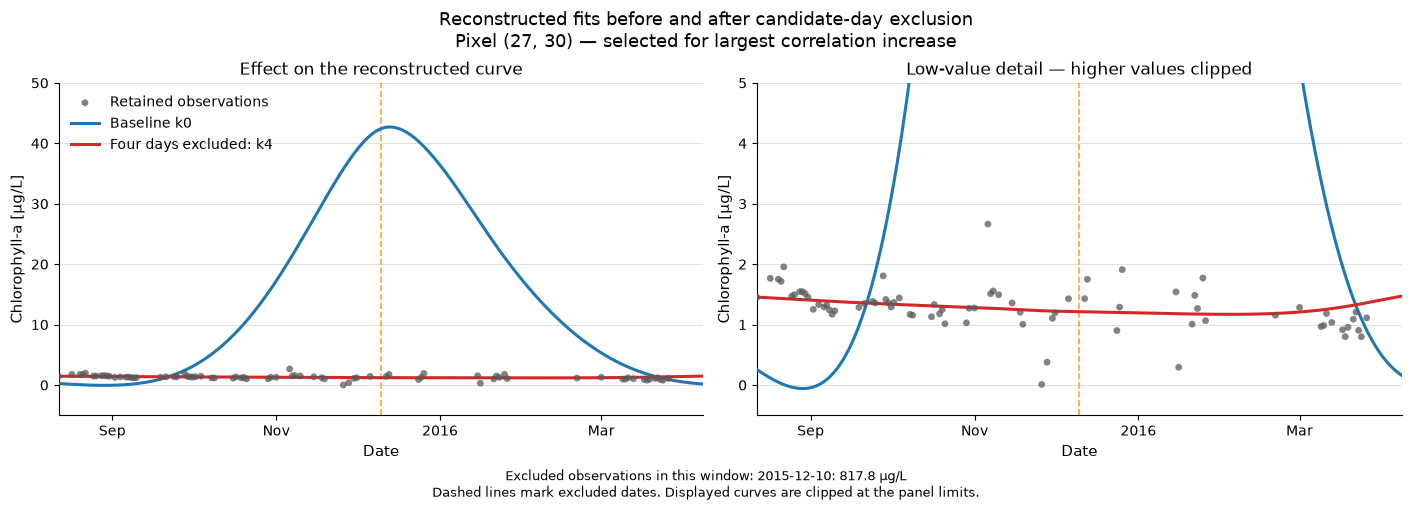

In [13]:
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    constrained_layout=True,
)

local_retained = (
    retained
    & (baseline["dates"] >= left)
    & (baseline["dates"] <= right)
)

local_removed = (
    removed
    & (baseline["dates"] >= left)
    & (baseline["dates"] <= right)
)

for ax in axes:
    ax.scatter(
        baseline["dates"][local_retained],
        baseline["values"][local_retained],
        s=24,
        color="0.35",
        alpha=0.75,
        edgecolors="none",
        label="Retained observations",
        zorder=4,
    )

    for series, color, name in [
        (baseline, "tab:blue", "Baseline k0"),
        (variant, "tab:red", "Four days excluded: k4"),
    ]:
        local_curve = (
            (series["curve_dates"] >= left)
            & (series["curve_dates"] <= right)
        )

        ax.plot(
            series["curve_dates"][local_curve],
            series["curve_values"][local_curve],
            color=color,
            linewidth=2.2,
            label=name,
            zorder=3,
        )

    ax.scatter(
        baseline["dates"][local_removed],
        baseline["values"][local_removed],
        color="darkorange",
        marker="x",
        s=70,
        linewidths=2,
        zorder=5,
    )

    for date in baseline["dates"][local_removed]:
        ax.axvline(
            date,
            color="darkorange",
            linestyle="--",
            linewidth=1.2,
            alpha=0.8,
        )

    ax.set_xlim(left, right)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("Chlorophyll-a [µg/L]", fontsize=11)

    locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.minorticks_off()
    ax.grid(axis="y", color="0.88", linewidth=0.7)
    ax.tick_params(labelsize=10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylim(-5, 50)
axes[0].yaxis.set_major_locator(MultipleLocator(10))
axes[0].set_title("Effect on the reconstructed curve", fontsize=12)

axes[1].set_ylim(-0.5, 5)
axes[1].yaxis.set_major_locator(MultipleLocator(1))
axes[1].set_title(
    "Low-value detail — higher values clipped",
    fontsize=12,
)

axes[0].legend(
    loc="upper left",
    frameon=False,
    fontsize=10,
)

excluded_notes = [
    f"{date.date()}: {value:.1f} µg/L"
    for date, value in zip(
        baseline["dates"][local_removed],
        baseline["values"][local_removed],
    )
]

note = (
    "Excluded observations in this window: "
    + "; ".join(excluded_notes)
    if excluded_notes
    else "No excluded valid observation in this window."
)

fig.suptitle(
    f"Reconstructed fits before and after candidate-day exclusion\n"
    f"Pixel ({i}, {j}) — selected for largest correlation increase",
    fontsize=13,
)

fig.supxlabel(
    note + "\n"
    "Dashed lines mark excluded dates. "
    "Displayed curves are clipped at the panel limits.",
    fontsize=9,
)

fig.savefig(
    plot_dir / "k0_vs_k4_two_scales.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

### Result first exploratory run WITHOUT 2008-12-13!!!

The baseline contains 982 pixels with a valid correlation.
At least 20 pixels must improve by 0.10 or more to reach
the 2% success threshold.

None of the tested variants meets this criterion.
The largest number of improved pixels relative to the baseline
is 16 (1.63%), reached by k4 and k5.

This result applies to our selected candidate order and our
baseline-pixel denominator. It does not prove that the candidate
observations are valid or invalid.

## 8. Random-day controls

As a comparison, three control runs each remove five randomly
selected days instead of the five candidate days.

Random days were selected from days with at least 500 valid
pixels, excluding the five selected candidate days.
They were not individually verified as outlier-free.

Each control is compared with the baseline (k0).
These controls help put the candidate-removal results into context,
but three runs are not sufficient for a firm statistical conclusion.

The control fits were completed earlier.
Only their correlations are calculated below.

In [ ]:
# Names of the three random-day control runs.
control_names = ["_r1", "_r2", "_r3"]

# Check that the input and phenology output files exist
# for every random-day control.
for name in control_names:
    run_dir = outlier_dir / f"k{name}"
    input_file = run_dir / "extract" / "chla" / "327.nc"
    fit_file = run_dir / "phenology" / "chla" / "327.nc"

    print(
        f"{name}: input exists = {input_file.is_file()}, "
        f"fit exists = {fit_file.is_file()}"
    )

    assert input_file.is_file(), f"Missing input file: {input_file}"
    assert fit_file.is_file(), f"Missing fit file: {fit_file}"

# Calculate correlations from the completed control fits.
random_correlations = {}

for name in control_names:
    print(f"Calculating correlations for {name}...", flush=True)
    random_correlations[name] = corr_map(name)

print("Random-control correlation calculation complete.")

_r1: input exists = True, fit exists = True
_r2: input exists = True, fit exists = True
_r3: input exists = True, fit exists = True
Calculating correlations for _r1...


c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)


Calculating correlations for _r2...
Calculating correlations for _r3...
Random-control correlation calculation complete.


In [ ]:
# Compare candidate removal and random removal with the same baseline.
variants = {"candidates_k5": c[5]}
variants.update(random_correlations)

rows = []

for name, correlation in variants.items():
    change = correlation - c[0]
    comparable = baseline_pixels & np.isfinite(change)

    rows.append({
        "variant": name,
        "comparable_pixels": int(comparable.sum()),
        "improved_ge_0.10": int(np.sum(
            comparable & (change >= 0.10)
        )),
        "improved_ge_0.05": int(np.sum(
            comparable & (change >= 0.05)
        )),
        "improved_ge_0.02": int(np.sum(
            comparable & (change >= 0.02)
        )),
        "worsened_le_-0.05": int(np.sum(
            comparable & (change <= -0.05)
        )),
    })

control_results = pd.DataFrame(rows)
print(control_results.to_string(index=False))

      variant  comparable_pixels  improved_ge_0.10  improved_ge_0.05  improved_ge_0.02  worsened_le_-0.05
candidates_k5                982                16                47                89                 35
          _r1                982                 7                15                39                 21
          _r2                982                 8                34                71                 27
          _r3                982                 9                32                66                 27
